# <font face = 'Impact' color = '#FFAEBC' > Sample Demonstration on Machine Learning for Regression<font/>
#### <font face = 'Times New Roman' color = '#B5E5CF'> License: GPL v3.0<font/>
#### <font face = 'Times New Roman' color = '#B5E5CF'> Author and Trainer: Paolo Hilado MSc. (Data Science)<font/>
This notebook provides a backgrounder in doing Machine Learning in Python employing models such as Ridge Regression, LASSO Regression, Elastic Net, and Random Forest Regressor.

#### <font face = 'Times New Roman' color = '#B5E5CF'> Name of Business Analyst: Florence Elaine G. Soleño<font/>
#### <font face = 'Times New Roman' color = '#B5E5CF'> Date of Accomplishment: September 16, 2026<font/>

# <font face = 'Palatino Linotype' color = '#5885AF'> Business Understanding:<font/>

### <font face = 'Palatino Linotype' color = '#5885AF'> A. Business Context <font/>

This case is set in the financial services sector, where the hypothetical organization seeks to understand and predict the financial health and creditworthiness of hypothetical businesses in order to make informed lending and investment decisions. Specifically, the objective is to predict a company's CreditRiskScore — a quantitative measure of the likelihood of default or financial instability — based on historical financial, operational, and regional characteristics.

The dataset provided contains information on companies' financial performance (AnnualRevenue, ProfitMargin), size and operational history (NumEmployees, YearsInOperation), prior financial behavior (HasPreviousDefaults, AvgMonthlyDebtObligation, CurrentLoanAmount), asset backing (CollateralValue), quality of financial reporting (FinancialStatementQuality), and contextual factors such as Industry and Region.

By building a regression model using these predictor variables, the organization aims to:

Identify the key drivers of credit risk.

Quantify the relationship between company characteristics and creditworthiness.

Support data-driven lending decisions, risk assessment, and portfolio management.

Reduce the likelihood of loan defaults and optimize capital allocation.

The business goal is therefore to develop a predictive model that accurately estimates the CreditRiskScore for each company, enabling management to make strategic financial decisions with greater confidence.



### <font face = 'Palatino Linotype' color = '#5885AF'> B. Business Problem <font/>

Companies with similar profiles can carry very different levels of credit risk, and CreditRiskScore cannot be reliably inferred from any single financial metric. Lending and investment decisions therefore require a consistent, quantitative basis for comparing companies.

Because all companies in the dataset are already being assessed, the problem is not to determine loan eligibility. The focus is whether the available financial, operational, and regional information can explain and predict a company's CreditRiskScore — enabling earlier identification of high-risk applicants, more consistent risk assessment, and stronger portfolio monitoring.


### <font face = 'Palatino Linotype' color = '#5885AF'> C. Business Objectives <font/>


* Enhance risk assessment by improving the estimation of CreditRiskScore using company financial, operational, and contextual data.

* Optimize lending decisions by flagging high-risk companies for closer review or adjusted terms.

* Improve capital allocation by prioritizing creditworthy applicants and optimizing the risk-return profile of the portfolio.

* Standardize decision support by providing a reliable, data-backed basis for consistent credit assessment.


### <font face = 'Palatino Linotype' color = '#5885AF'> D. Data Mining Objectives <font/>


* Build a regression model predicting CreditRiskScore from company data.

* Minimize prediction error, evaluated via CV, Train, and Test RMSE.

* Identify a minimal subset of high-impact variables that maintains performance.

* Extract interpretable relationships explaining how company factors contribute to credit risk.






### <font face = 'Palatino Linotype' color = '#5885AF'> E. Business Assumptions <font/>

* The dataset is representative of the target company population without major selection bias.

* Financial variables and categorical attributes are recorded accurately and consistently.

* CreditRiskScore accurately represents credit risk at assessment time.

* Higher revenue, profit margin, and operational history imply lower risk.

* Prior defaults, larger loan amounts, and higher debt obligations imply higher risk.

* Results will support but not replace professional credit judgment.


### <font face = 'Palatino Linotype' color = '#5885AF'> F. Success Criteria <font/>

Business Success Criteria

* Demonstrate that company data meaningfully predicts CreditRiskScore and supports credit assessment.

* Provide a reliable way to flag high-risk companies for closer review.

* Show that a reduced variable set performs close to the full set.

* Identify at least three meaningful risk factors that can be interpreted and used.

Data Mining Success Criteria

* Achieve Test R² ≥ 0.70, clearly above the mean-prediction baseline.

* Maintain stable performance across all cross-validation folds.

* Keep overfit gap (Train RMSE − CV RMSE) below 0.5.

* Retain Test R² within 5 percentage points when using a reduced feature set.

* Identify at least three consistent, explainable variables or patterns across validation.







# <font face = 'Palatino Linotype' color = '#5885AF'> Data Understanding:<font/>
Provide a solid data understanding section for this mini-project.

### <font face = 'Palatino Linotype' color = '#5885AF'> 2.1 Data Owner<font/>

The hypothetical data owner is the **Credit Risk Department** of a financial institution.
The department maintains historical information about companies' financial performance,
operational history, prior financial behavior, and contextual factors, along with their
associated `CreditRiskScore`.

This is an educational assignment so the dataset is synthetic and does not represent an actual company or proprietary database.

### <font face = 'Palatino Linotype' color = '#5885AF'> 2.2 Data Source <font/>

The dataset is hypothetical and synthetically generated for educational and demonstration
purposes. The variables and their approximate relationships are designed to resemble a
real-world credit risk dataset.

### <font face = 'Palatino Linotype' color = '#5885AF'> 2.3 Data Licensing<font/>

The dataset is used here for educational purposes only. No real company's financial
information or personal data is included. If this project were converted to real company
data, licensing and regulatory review (e.g., GDPR, Basel III, IFRS 9) would be required
before use.

### <font face = 'Palatino Linotype' color = '#5885AF'>2.4 Data Format<font/>

- **Format:** Excel (.xlsx)
- **Contains:** A mix of numerical, ordinal, binary, and categorical variables

### <font face = 'Palatino Linotype' color = '#5885AF'>2.5 Dataset Dimensions<font/>

- **Rows:** ~500 observations (companies)
- **Columns:** 12 (11 predictors + 1 target)

### <font face = 'Palatino Linotype' color = '#FFFFF'>2.6 Data Dictionary<font/>


| Variable | Data Type | Description | Role |
|---|---|---|---|
| `AnnualRevenue` | Float | Company annual revenue | Predictor |
| `ProfitMargin` | Float | Profit margin (%) | Predictor |
| `NumEmployees` | Float | Number of employees | Predictor |
| `YearsInOperation` | Float | Years the company has been operating | Predictor |
| `Industry` | Categorical | Industry sector (Healthcare, Manufacturing, Finance, Retail, Tech) | Predictor |
| `HasPreviousDefaults` | Binary (0/1) | Whether company has previous defaults | Predictor |
| `AvgMonthlyDebtObligation` | Float | Average monthly debt obligation | Predictor |
| `CurrentLoanAmount` | Float | Current loan amount | Predictor |
| `CollateralValue` | Float | Value of collateral | Predictor |
| `FinancialStatementQuality` | Ordinal (1–5) | Quality of financial reporting | Predictor |
| `Region` | Categorical | Geographic region (North, South, East, West) | Predictor |
| `CreditRiskScore` | Float | Credit risk score (0–100) | **Target** |

# <font face = 'Palatino Linotype' color = '#5885AF'> Data Preparation:<font/>
Indicate your recipe for data exploration and transformation in preparation for modelling.

In [47]:
# Load the necessary packages
import pandas as pd
import numpy as np

In [48]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_excel('/content/drive/MyDrive/BATT/credit_risk_score.xlsx')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [49]:
# Check dataset dimensions
print("=== DATASET DIMENSIONS ===")
print(f"Number of rows    : {df.shape[0]}")
print(f"Number of columns : {df.shape[1]}")
print(f"Total cells       : {df.size}")

=== DATASET DIMENSIONS ===
Number of rows    : 1000
Number of columns : 12
Total cells       : 12000


 I checked the dataset dimensions by printing the number of rows, columns, and total cells.

 The dataset has 1000 rows and 12 columns, totaling 12,000 cells, a moderately-sized data but large enough to train models meaningfully. A 5-fold cross-validation is a reasonable choice given this size.

In [50]:
# Check column names and data types
print("=== COLUMN NAMES AND DATA TYPES ===")
print(df.dtypes)

print("\n--- Summary ---")
print(f"Numeric columns     : {df.select_dtypes(include=['int64','float64']).shape[1]}")
print(f"Categorical columns : {df.select_dtypes(include=['object']).shape[1]}")

=== COLUMN NAMES AND DATA TYPES ===
AnnualRevenue                float64
ProfitMargin                 float64
NumEmployees                   int64
YearsInOperation               int64
Industry                         str
HasPreviousDefaults            int64
AvgMonthlyDebtObligation     float64
CurrentLoanAmount            float64
CollateralValue              float64
FinancialStatementQuality      int64
Region                           str
CreditRiskScore              float64
dtype: object

--- Summary ---
Numeric columns     : 10
Categorical columns : 2


 I needed to distinguish between numerical data (which may require scaling) and categorical text data (which requires encoding) before modeling so I examined the data type of each column and summarized the count of numeric versus categorical columns.

  This confirms my data dictionary and dictates my preprocessing plan. I will need to scale numeric features and one-hot encode categorical features.



In [51]:
# Preview the top and bottom of the dataset
print("=== FIRST 5 ROWS ===")
display(df.head())

print("\n=== LAST 5 ROWS ===")
display(df.tail())

=== FIRST 5 ROWS ===


,AnnualRevenue,ProfitMargin,NumEmployees,YearsInOperation,Industry,HasPreviousDefaults,AvgMonthlyDebtObligation,CurrentLoanAmount,CollateralValue,FinancialStatementQuality,Region,CreditRiskScore
0,5.372018e+06,16.996777,48,19,Healthcare,0,20384.398702,579814.337716,825939.405284,5,West,10.554537
1,2.846884e+06,14.623168,47,26,Manufacturing,0,29319.250061,507097.856107,93672.826723,4,East,67.298342
2,6.247479e+06,10.298152,50,26,Healthcare,0,22538.061802,548087.263041,809158.936975,3,North,11.682366
3,1.499204e+07,6.765316,37,25,Healthcare,1,14843.385363,767623.082354,932309.562351,5,North,0.000000
4,2.586579e+06,13.491117,57,26,Finance,0,4870.969105,501459.017855,54753.956543,3,North,68.996762



=== LAST 5 ROWS ===


,AnnualRevenue,ProfitMargin,NumEmployees,YearsInOperation,Industry,HasPreviousDefaults,AvgMonthlyDebtObligation,CurrentLoanAmount,CollateralValue,FinancialStatementQuality,Region,CreditRiskScore
995,2.467953e+06,15.350751,56,31,Retail,0,13528.781186,600250.692972,489360.449550,2,South,63.383308
996,1.973070e+07,9.867394,66,28,Finance,0,10664.892767,80849.337381,764753.459035,5,South,0.000000
997,6.204857e+06,5.590627,52,39,Manufacturing,0,193.025620,457355.176219,563406.397763,2,North,6.090258
998,1.846534e+06,9.184665,34,1,Manufacturing,0,23177.594689,436342.155730,568722.315325,2,South,65.771953
999,5.795445e+06,6.275487,49,25,Healthcare,0,17906.969281,279348.486388,708403.448772,4,West,6.064434


I displayed the first 5 and last 5 rows of the DataFrame to visually inspect the data to check for obvious formatting issues, strange values, or inconsistencies.

The data appears clean and well-formatted but I noticed that CreditRiskScore contains several zeros.

In [52]:
# Summary statistics for numeric variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
AnnualRevenue,1000.0,6.093807e+06,1.242655e+07,127865.301903,1.728085e+06,3.377052e+06,6.321342e+06,2.604668e+08
ProfitMargin,1000.0,1.035418e+01,4.987272e+00,-4.701943,6.968792e+00,1.031539e+01,1.364441e+01,2.596554e+01
NumEmployees,1000.0,4.979000e+01,7.057741e+00,31.000000,4.500000e+01,4.900000e+01,5.425000e+01,7.400000e+01
YearsInOperation,1000.0,2.457000e+01,1.407868e+01,1.000000,1.200000e+01,2.400000e+01,3.700000e+01,4.900000e+01
HasPreviousDefaults,1000.0,8.800000e-02,2.834367e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
AvgMonthlyDebtObligation,1000.0,2.001358e+04,7.812036e+03,-7735.233255,1.464856e+04,2.013077e+04,2.536064e+04,4.239184e+04
CurrentLoanAmount,1000.0,4.998633e+05,2.013243e+05,-239324.381138,3.659646e+05,5.061945e+05,6.341132e+05,1.182837e+06
CollateralValue,1000.0,5.832578e+05,2.569151e+05,-256448.838208,4.038677e+05,5.918369e+05,7.505980e+05,1.402192e+06
FinancialStatementQuality,1000.0,3.028000e+00,1.425218e+00,1.000000,2.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00
CreditRiskScore,1000.0,3.805744e+01,2.747053e+01,0.000000,1.044529e+01,4.159461e+01,5.978825e+01,1.000000e+02


 I generated descriptive statistics to understand the central tendency, spread, and range of each numerical feature and the target variable.

Several variables have very wide ranges that reuires the need for feature scaling. The 0-100 range of the target suggests it behaves like a bounded score, which is useful context for interpreting model errors.

In [53]:
# Inspect categorical variables
categorical_cols = df.select_dtypes(include=["object"]).columns
print("Categorical columns:", categorical_cols.tolist())

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())
    print(f"Unique values: {df[col].nunique()}")

Categorical columns: ['Industry', 'Region']

--- Industry ---
Industry
Finance          233
Retail           195
Tech             194
Healthcare       193
Manufacturing    185
Name: count, dtype: int64
Unique values: 5

--- Region ---
Region
North    259
East     254
South    251
West     236
Name: count, dtype: int64
Unique values: 4


I checked the unique values and their frequency counts for Industry and Region. Industry has 5 unique values and Region has 4. The data is relatively balanced across these categories.

One-hot encoding is a suitable approach here. It will not create an excessively large number of new features, and the balanced classes mean no category will be unfairly underrepresented in the model.


In [54]:
# Summary for categorical columns
print("=== DESCRIPTIVE STATISTICS (CATEGORICAL) ===")

categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(f"Unique values : {df[col].nunique()}")
    print(f"Most frequent : {df[col].mode()[0]} (appears {df[col].value_counts().iloc[0]} times)")
    print(f"Missing       : {df[col].isnull().sum()}")
    print(f"\nValue counts:")
    print(df[col].value_counts())

=== DESCRIPTIVE STATISTICS (CATEGORICAL) ===

--- Industry ---
Unique values : 5
Most frequent : Finance (appears 233 times)
Missing       : 0

Value counts:
Industry
Finance          233
Retail           195
Tech             194
Healthcare       193
Manufacturing    185
Name: count, dtype: int64

--- Region ---
Unique values : 4
Most frequent : North (appears 259 times)
Missing       : 0

Value counts:
Region
North    259
East     254
South    251
West     236
Name: count, dtype: int64


 I wanted a more detailed description of the categorical features and to confirm there were no missing values. The distribution of categories is reasonably even, with no single category dominating.

 Meaning, I can skip any categorical imputation steps and the balanced distribution is already good for modeling  as it reduces bias toward a majority class.

In [55]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
AnnualRevenue                0
ProfitMargin                 0
NumEmployees                 0
YearsInOperation             0
Industry                     0
HasPreviousDefaults          0
AvgMonthlyDebtObligation     0
CurrentLoanAmount            0
CollateralValue              0
FinancialStatementQuality    0
Region                       0
CreditRiskScore              0
dtype: int64


There are zero missing values in the entire dataset.

In [56]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 0


The data is exceptionally clean from missing values and exact duplicates.

I can skip the data imputation step entirely. No rows also needs to be dropped.

In [57]:
# Check for duplicates in key columns
print("=== DUPLICATE CHECK ON KEY COLUMNS ===")


key_cols = ["AnnualRevenue", "ProfitMargin", "NumEmployees"]
dup_keys = df.duplicated(subset=key_cols).sum()
print(f"Duplicate combinations on {key_cols}: {dup_keys}")

=== DUPLICATE CHECK ON KEY COLUMNS ===
Duplicate combinations on ['AnnualRevenue', 'ProfitMargin', 'NumEmployees']: 0


Each row appears to represent a unique company. Zero duplicate combinations exist.

In [58]:
# Check binary and ordinal variables
binary_ordinal_cols = ["HasPreviousDefaults", "FinancialStatementQuality"]

for col in binary_ordinal_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().sort_index())
    print(f"Unique values: {df[col].nunique()}")


--- HasPreviousDefaults ---
HasPreviousDefaults
0    912
1     88
Name: count, dtype: int64
Unique values: 2

--- FinancialStatementQuality ---
FinancialStatementQuality
1    193
2    213
3    176
4    209
5    209
Name: count, dtype: int64
Unique values: 5


HasPreviousDefaults should be treated as a binary feature and should NOT be scaled.

The ordinal nature of FinancialStatementQuality means it can be treated as a numerical feature for the models I plan to use.




In [59]:
# Target variable distribution
print("Target: CreditRiskScore")
print(df["CreditRiskScore"].describe())

# Count of zeros
zero_count = (df["CreditRiskScore"] == 0).sum()
print(f"\nNumber of exact zeros: {zero_count} ({zero_count/len(df)*100:.1f}%)")

# Count of 100s (if any)
hundred_count = (df["CreditRiskScore"] == 100).sum()
print(f"Number of exact 100s: {hundred_count} ({hundred_count/len(df)*100:.1f}%)")

Target: CreditRiskScore
count    1000.000000
mean       38.057442
std        27.470532
min         0.000000
25%        10.445294
50%        41.594607
75%        59.788254
max       100.000000
Name: CreditRiskScore, dtype: float64

Number of exact zeros: 197 (19.7%)
Number of exact 100s: 5 (0.5%)


I checked descriptive statistics and counted the number of exact zeros and 100s in the target variable CreditRiskScore to understand the target's distribution. Zero-inflation (many zeros) can be problematic for certain models.

The target is zero-inflated. This could bias linear models that expect a continuous, spread-out distribution. This can suggest that non-linear models might perform better.

In [60]:
# Check skewness of numeric variables
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

skewness = df[numeric_cols].skew().sort_values(ascending=False)
print("Skewness of numeric variables:")
print(skewness)

Skewness of numeric variables:
AnnualRevenue                11.981501
HasPreviousDefaults           2.913001
NumEmployees                  0.204503
YearsInOperation              0.050889
CreditRiskScore              -0.010750
FinancialStatementQuality    -0.016102
ProfitMargin                 -0.049396
CurrentLoanAmount            -0.063490
AvgMonthlyDebtObligation     -0.096544
CollateralValue              -0.110115
dtype: float64


I wanted to identify highly skewed distributions, as these can negatively affect linear models that assume normality.

A log transformation for AnnualRevenue could improve linear model performance. However, tree-based models are generally robust to skewness, so I may not need to transform it for Random Forest.



In [61]:
!pip install qdesc

In [62]:
# Import visualization libraries for EDA
import matplotlib.pyplot as plt
import seaborn as sns
import qdesc as qd


--- Variable: AnnualRevenue ---
  Anderson-Darling Statistic : 162.5143
  p-value : 0.0100
  Decision : Reject Null


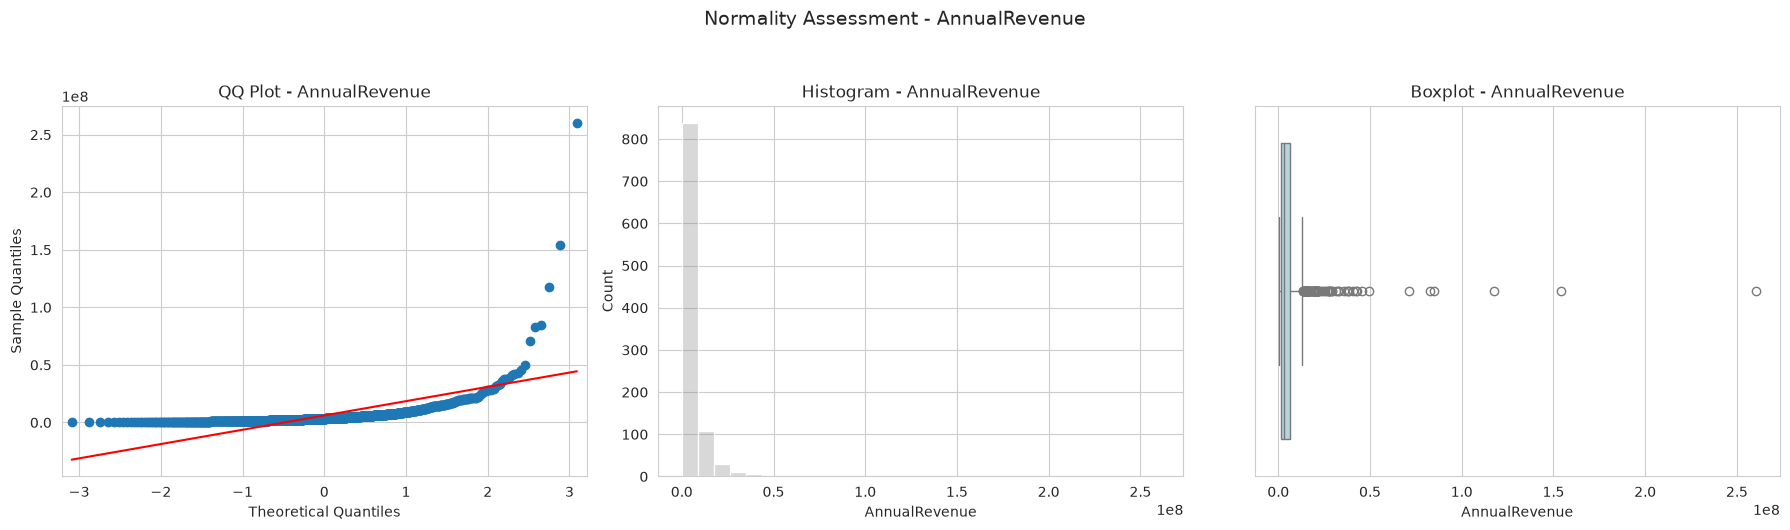


--- Variable: ProfitMargin ---
  Anderson-Darling Statistic : 0.1739
  p-value : 0.1500
  Decision : Fail to Reject Null


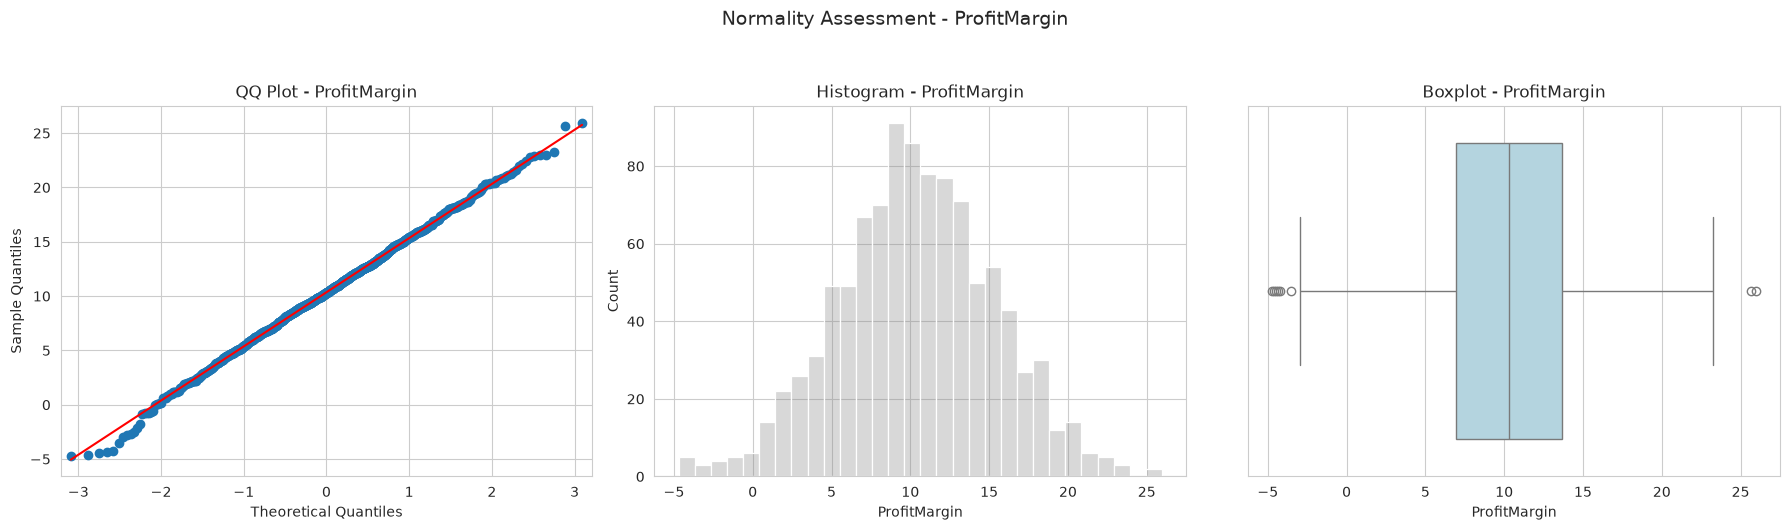


--- Variable: NumEmployees ---
  Anderson-Darling Statistic : 1.6986
  p-value : 0.0100
  Decision : Reject Null


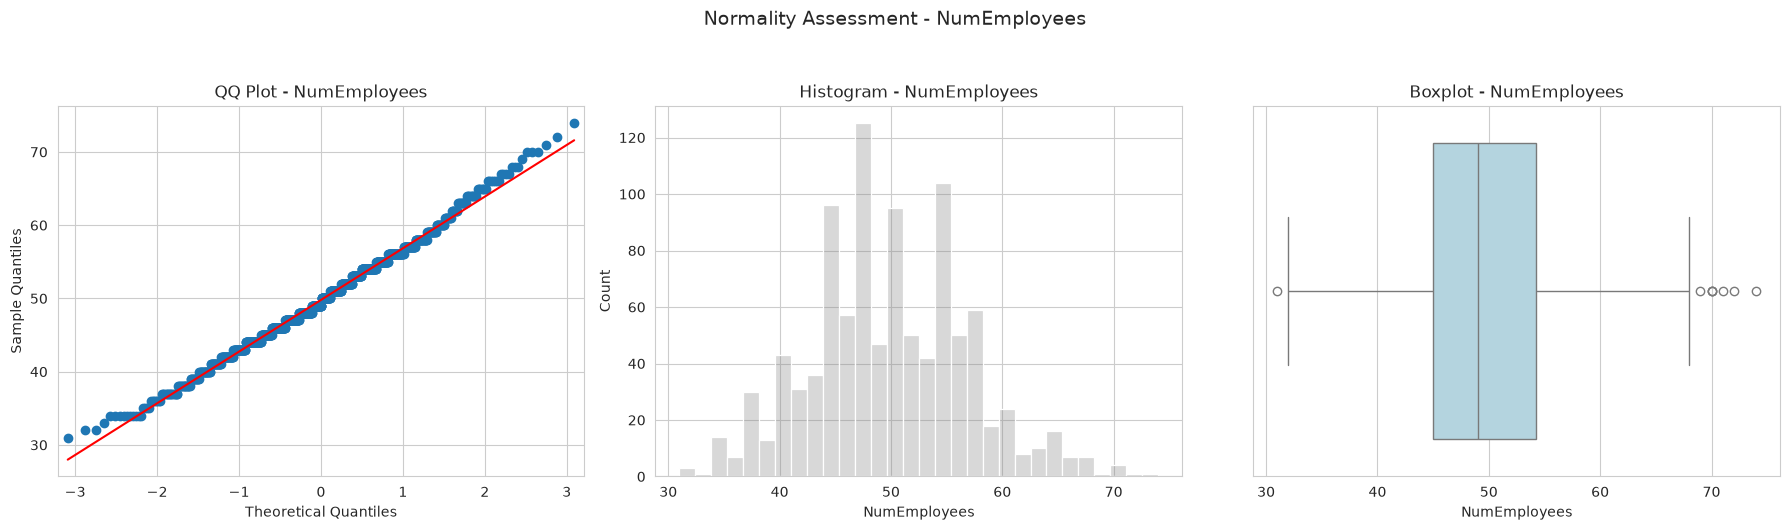


--- Variable: YearsInOperation ---
  Anderson-Darling Statistic : 11.5829
  p-value : 0.0100
  Decision : Reject Null


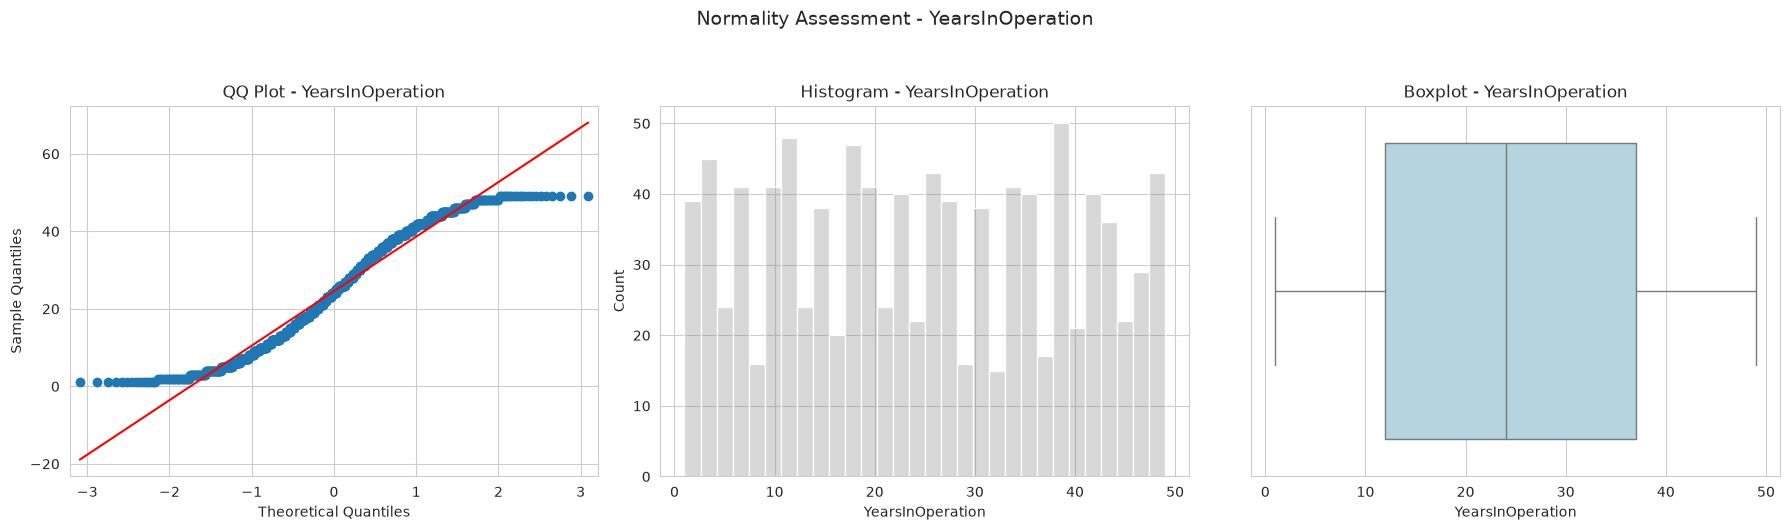


--- Variable: HasPreviousDefaults ---
  Anderson-Darling Statistic : 337.2327
  p-value : 0.0100
  Decision : Reject Null


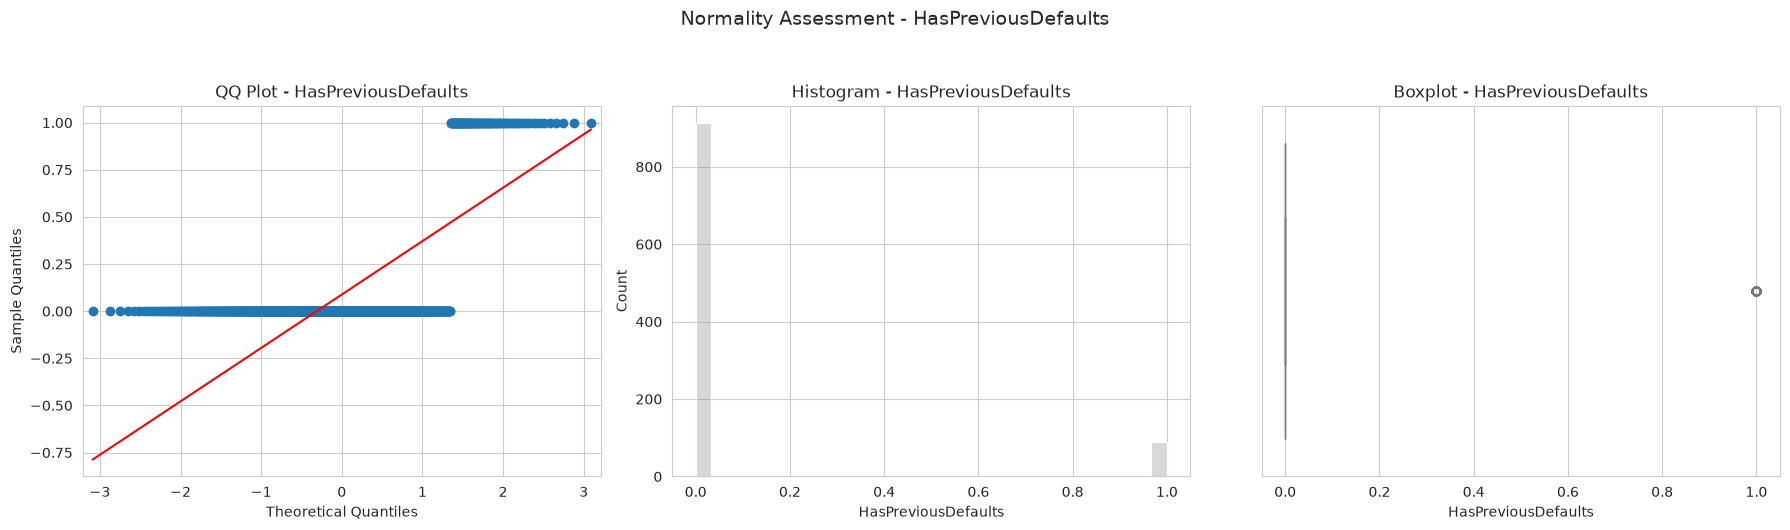


--- Variable: AvgMonthlyDebtObligation ---
  Anderson-Darling Statistic : 0.2482
  p-value : 0.1500
  Decision : Fail to Reject Null


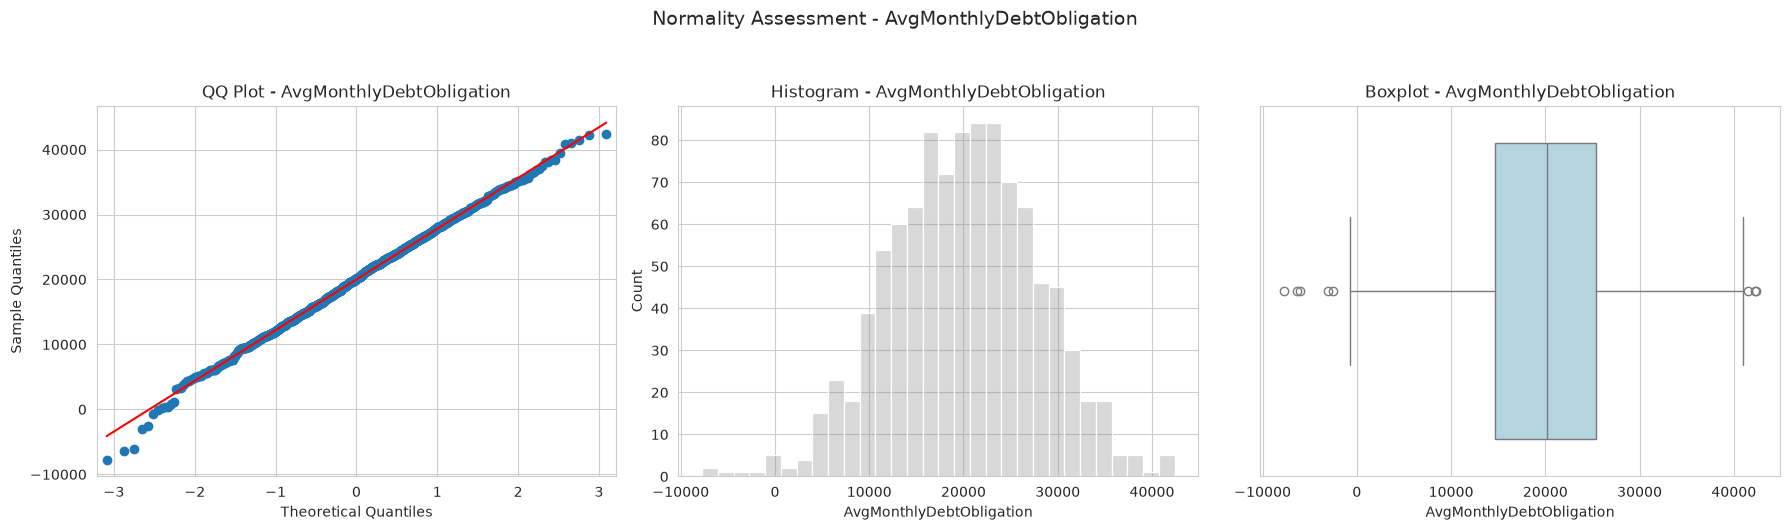


--- Variable: CurrentLoanAmount ---
  Anderson-Darling Statistic : 0.2148
  p-value : 0.1500
  Decision : Fail to Reject Null


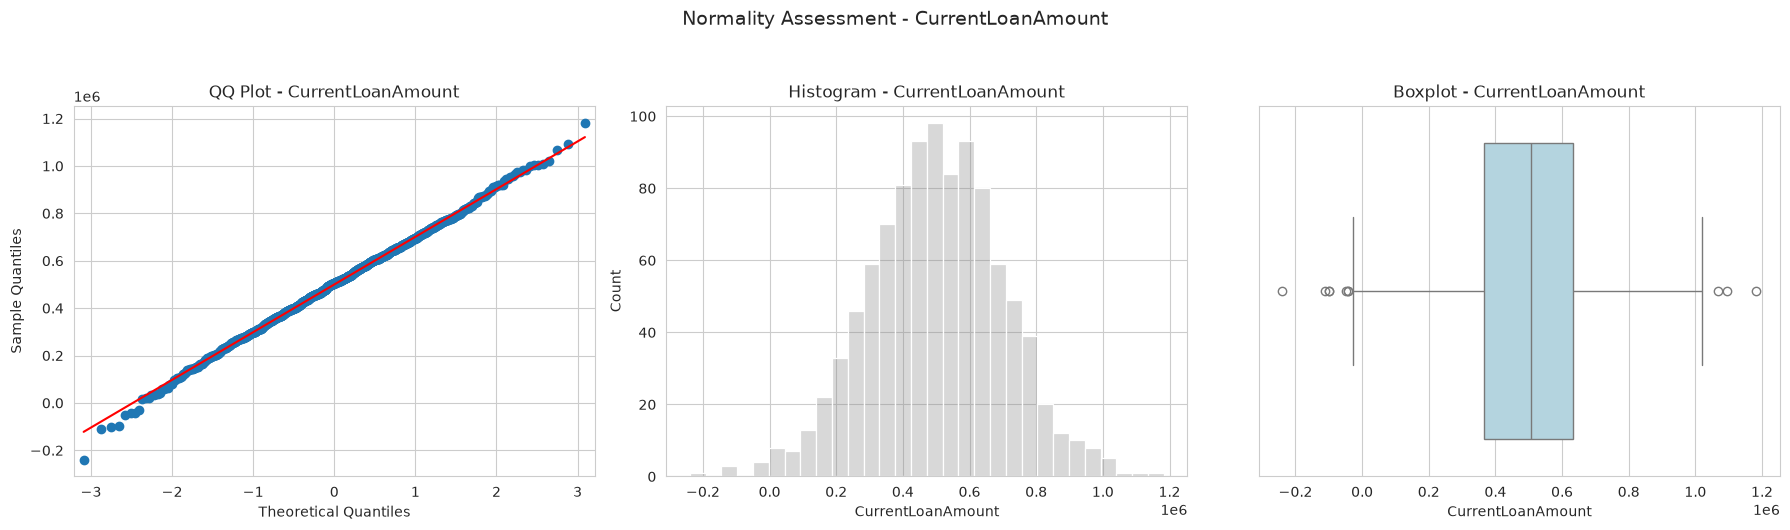


--- Variable: CollateralValue ---
  Anderson-Darling Statistic : 0.5649
  p-value : 0.1472
  Decision : Fail to Reject Null


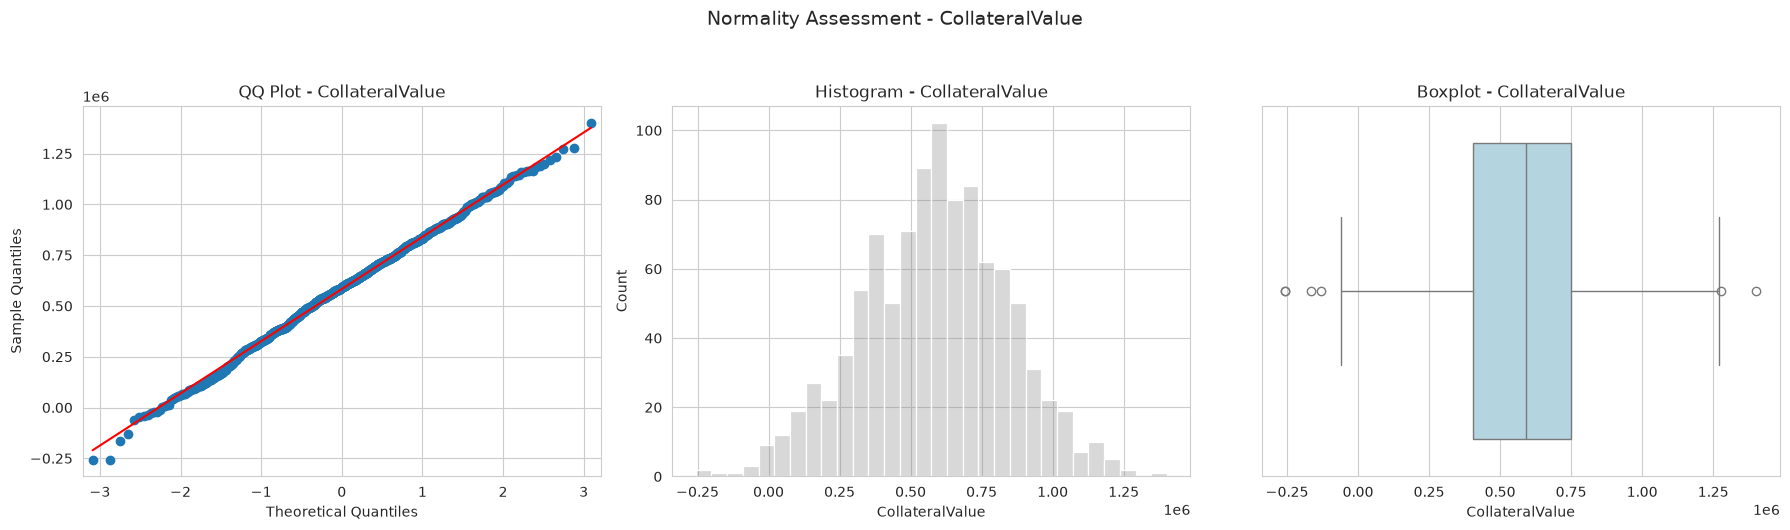


--- Variable: FinancialStatementQuality ---
  Anderson-Darling Statistic : 37.7107
  p-value : 0.0100
  Decision : Reject Null


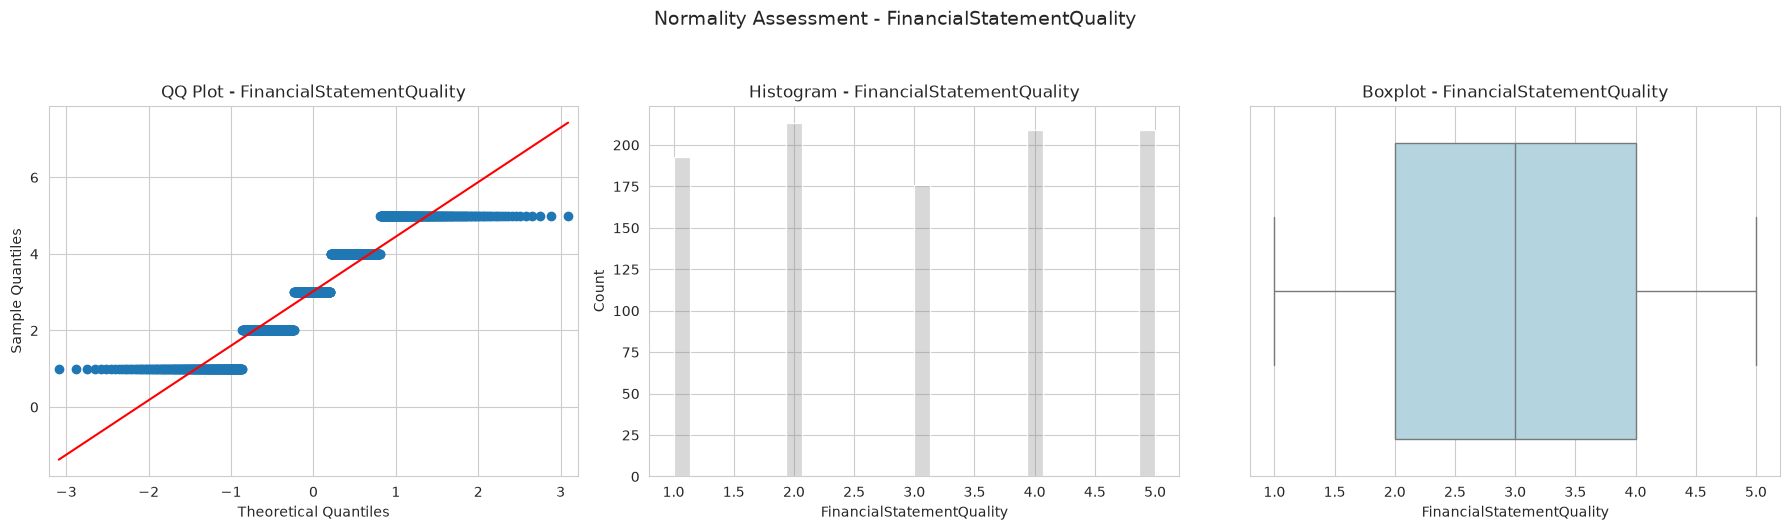


--- Variable: CreditRiskScore ---
  Anderson-Darling Statistic : 20.2235
  p-value : 0.0100
  Decision : Reject Null


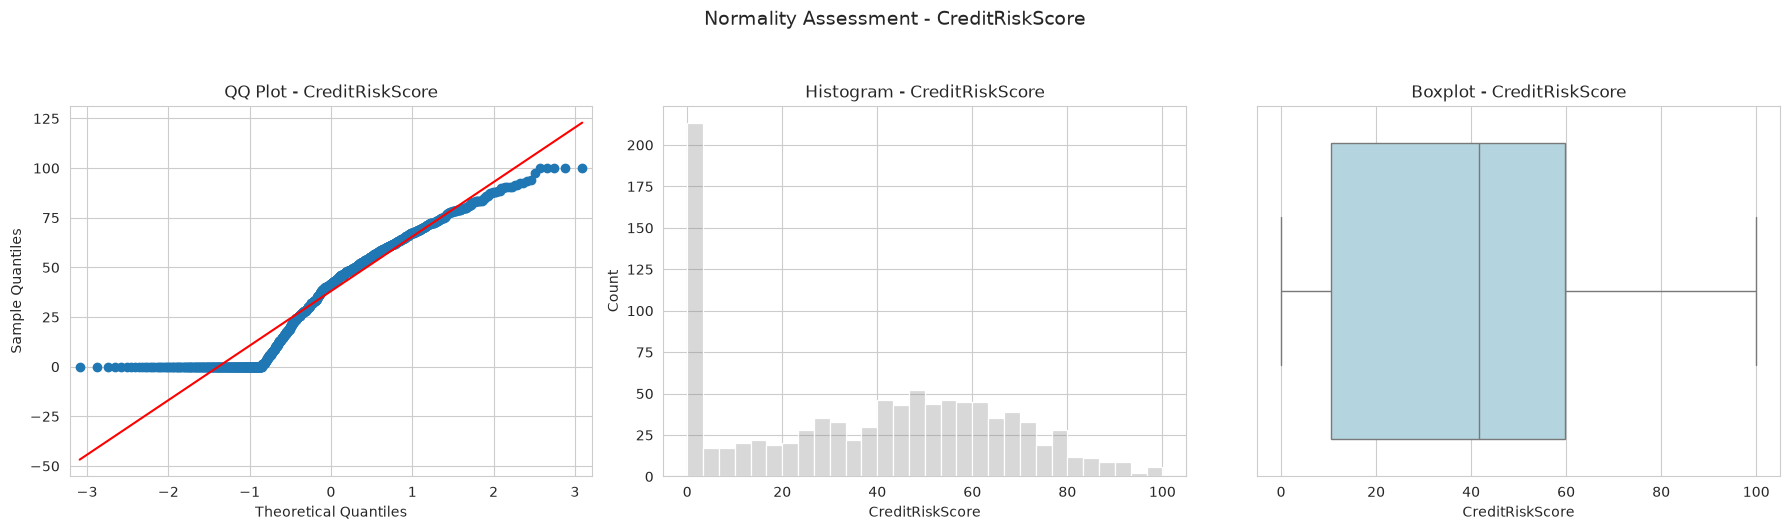

In [63]:
qd.normcheck_dashboard(df)

Most variables, including the target, are not normally distributed (p-value < 0.05). The plots confirm the skewness and zero-inflation I saw earlier.

The assumption of normality is violated. This reinforces my decision to use models that do not strictly require normality (like regularized regression and tree-based models). It also suggests that non-linear models will likely perform better.

I will use Spearman Correlation for this dataset since assumption of normality is violated

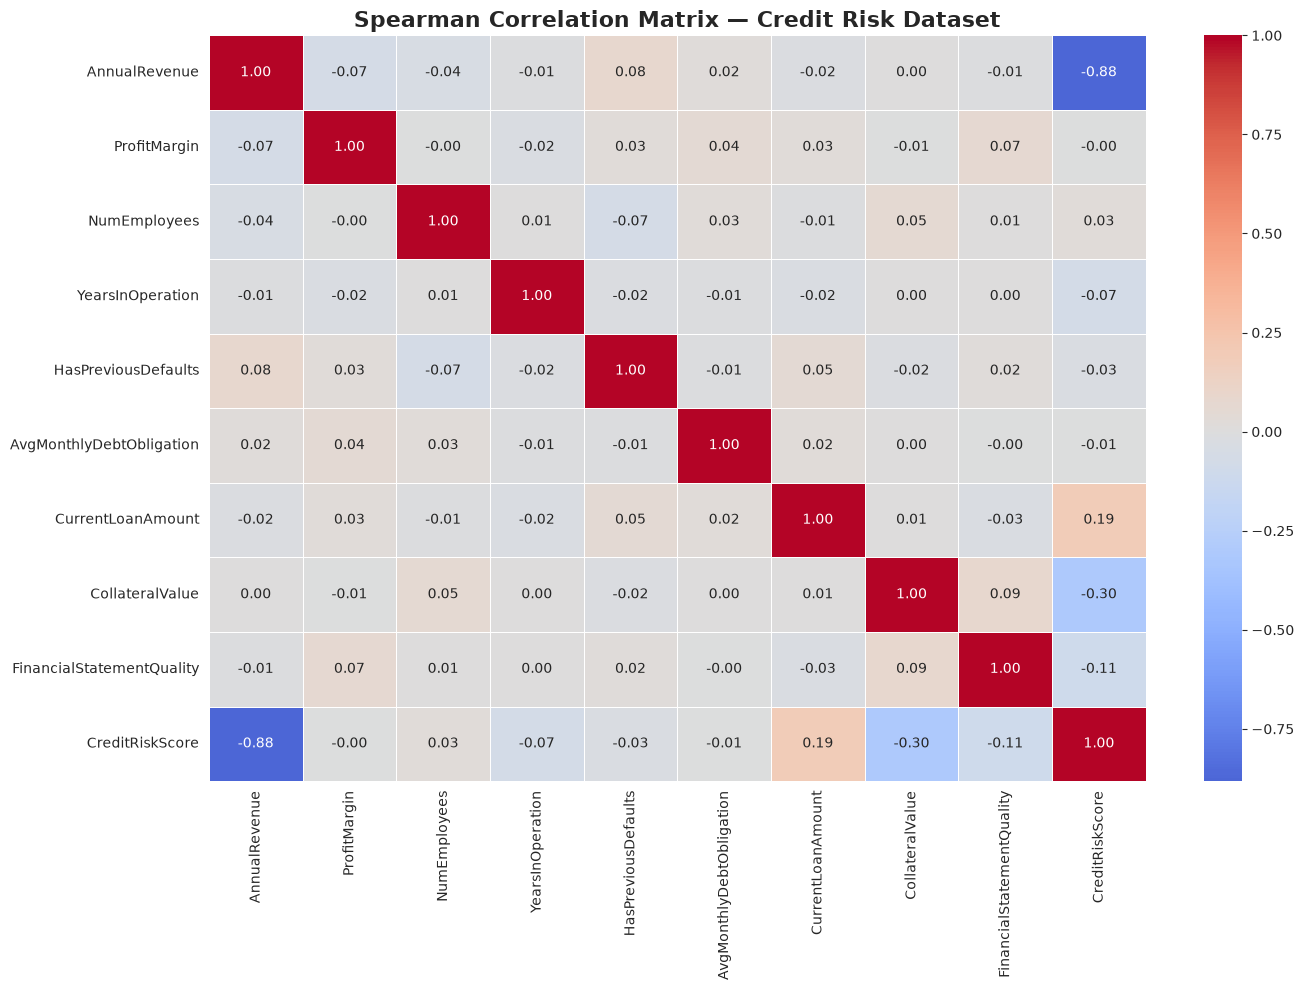

In [64]:
# Set display style
sns.set_style("whitegrid")

# Select only numerical features
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Calculate correlation matrix using Spearman (robust to non-normality and outliers)
correlation_matrix = numeric_df.corr(method="spearman")

# Set figure size
plt.figure(figsize=(14, 10))

# Create heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

# Add title
plt.title(
    "Spearman Correlation Matrix — Credit Risk Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

 I used Spearman instead of Pearson because it captures monotonic relationships and is robust to outliers, which is more appropriate given the non-normality of my data.

 The correlations between predictors and the target are generally weak, with none exceeding ±0.35. The strongest correlation with CreditRiskScore is from CollateralValue.

 The low correlation between predictors means multicollinearity is likely not an issue.

In [65]:
# Import libraries for VIF
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Select numeric explanatory variables (drop target)
X_vif = df.select_dtypes(include=["int64", "float64"]).drop(columns=["CreditRiskScore"])

# 2. Standardize the explanatory variables (VIF is scale-sensitive)
scaler_vif = StandardScaler()
X_scaled = scaler_vif.fit_transform(X_vif)

# Convert back to DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=X_vif.columns,
    index=X_vif.index
)

# 3. Add intercept
X_constant = sm.add_constant(X_scaled)

# 4. Calculate VIF for each feature
vif = pd.DataFrame()
vif["Feature"] = X_constant.columns
vif["VIF"] = [
    variance_inflation_factor(X_constant.values, i)
    for i in range(X_constant.shape[1])
]

# 5. Remove intercept and sort descending
vif = vif[vif["Feature"] != "const"]
vif = vif.sort_values(by="VIF", ascending=False).reset_index(drop=True)

# Display results
display(vif)

,Feature,VIF
0,FinancialStatementQuality,1.012383
1,HasPreviousDefaults,1.010315
2,CollateralValue,1.009685
3,ProfitMargin,1.008150
4,NumEmployees,1.007971
5,CurrentLoanAmount,1.007476
6,AnnualRevenue,1.005447
7,AvgMonthlyDebtObligation,1.004847
8,YearsInOperation,1.001172


VIF detects multicollinearity (high correlation among predictors), which can make linear models unstable and hard to interpret.


All VIF scores are very close to 1 so there is no multicollinearity.

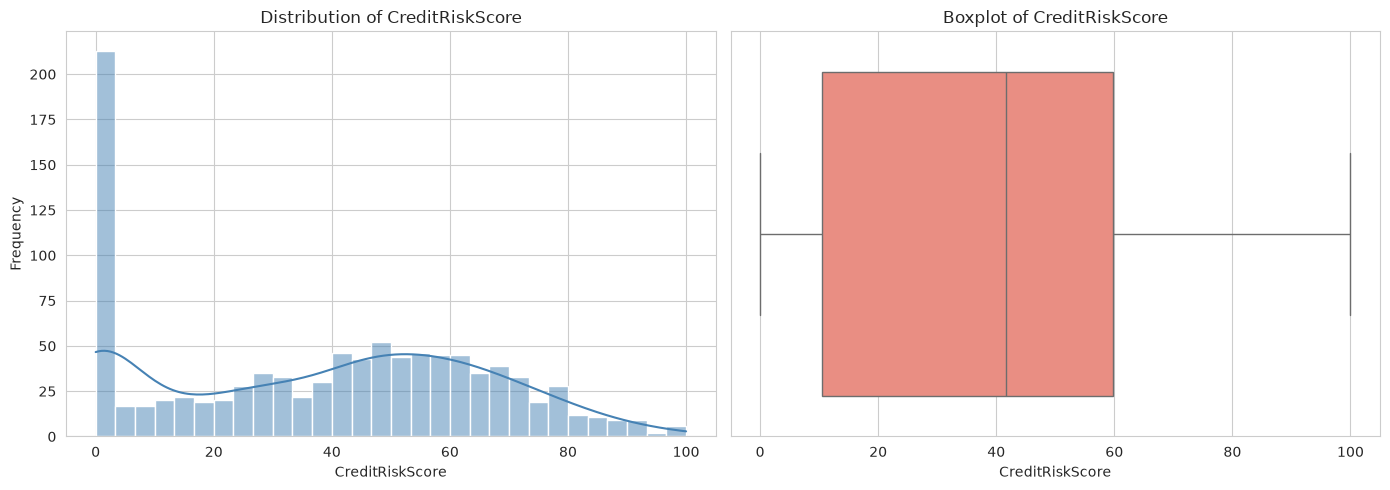

Number of exact zeros: 197 (19.7%)
Target mean: 38.06
Target median: 41.59
Target range: 0.00 to 100.00


In [66]:
# Plot the target variable distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(df["CreditRiskScore"], bins=30, kde=True,
             color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of CreditRiskScore", fontsize=12)
axes[0].set_xlabel("CreditRiskScore")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(x=df["CreditRiskScore"], color="salmon", ax=axes[1])
axes[1].set_title("Boxplot of CreditRiskScore", fontsize=12)
axes[1].set_xlabel("CreditRiskScore")

plt.tight_layout()
plt.show()

# Quantify zero-inflation
zero_count = (df["CreditRiskScore"] == 0).sum()
print(f"Number of exact zeros: {zero_count} ({zero_count/len(df)*100:.1f}%)")
print(f"Target mean: {df['CreditRiskScore'].mean():.2f}")
print(f"Target median: {df['CreditRiskScore'].median():.2f}")
print(f"Target range: {df['CreditRiskScore'].min():.2f} to {df['CreditRiskScore'].max():.2f}")

 I wanted to visually inspect the distribution, bimodality, and potential outliers in the target. The plots clearly show a spike at 0 and a spread-out cluster for non-zero values.

 This is a major reason why I would expect the non-linear Random Forest model to outperform the linear models, as it can better capture this complex pattern.





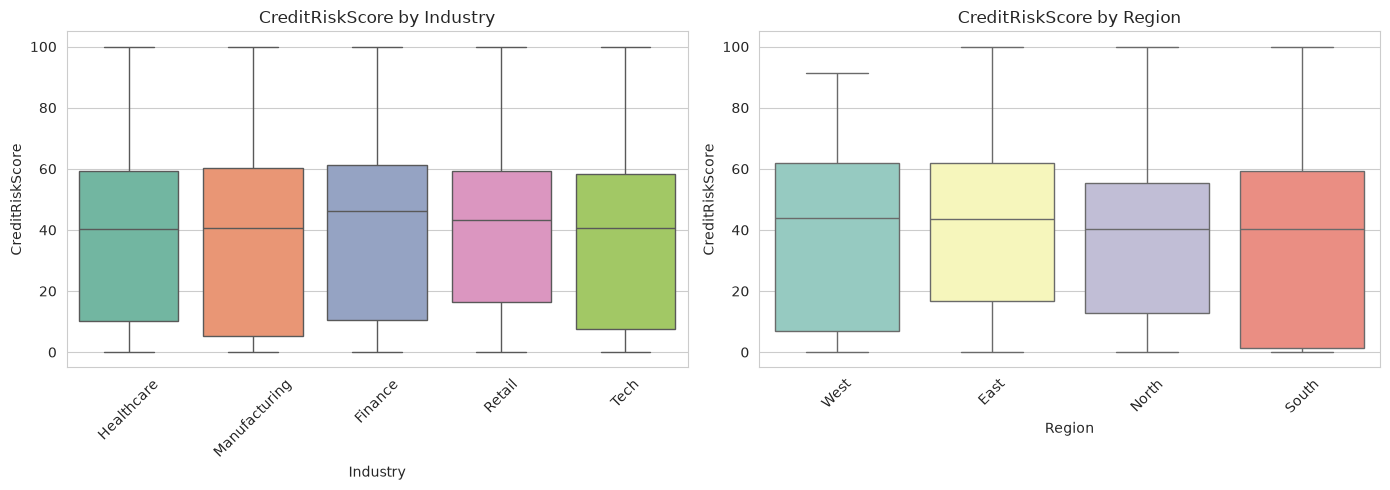

Mean CreditRiskScore by Industry:
Industry
Finance          39.840807
Retail           39.389029
Manufacturing    37.172256
Healthcare       37.045313
Tech             36.428149
Name: CreditRiskScore, dtype: float64

Mean CreditRiskScore by Region:
Region
East     40.374647
West     38.706930
North    36.690861
South    36.512006
Name: CreditRiskScore, dtype: float64


In [67]:
# Boxplots: CreditRiskScore by Industry and Region
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Industry vs. target
sns.boxplot(data=df, x="Industry", y="CreditRiskScore",
            palette="Set2", ax=axes[0])
axes[0].set_title("CreditRiskScore by Industry", fontsize=12)
axes[0].tick_params(axis="x", rotation=45)

# Region vs. target
sns.boxplot(data=df, x="Region", y="CreditRiskScore",
            palette="Set3", ax=axes[1])
axes[1].set_title("CreditRiskScore by Region", fontsize=12)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics by category
print("Mean CreditRiskScore by Industry:")
print(df.groupby("Industry")["CreditRiskScore"].mean().sort_values(ascending=False))

print("\nMean CreditRiskScore by Region:")
print(df.groupby("Region")["CreditRiskScore"].mean().sort_values(ascending=False))

 The median credit risk scores are very similar across all industries and regions. The boxes overlap significantly.

 This suggests that Industry and Region might not be strong predictors of CreditRiskScore. This implies these features might be of low importance in my final model.

In [68]:
# Separate explanatory variables (X) and target variable (y)
X = df.drop(columns=["CreditRiskScore"])
y = df["CreditRiskScore"]

print("X dimensions:", X.shape)
print("y dimensions:", y.shape)

X dimensions: (1000, 11)
y dimensions: (1000,)


I separated the DataFrame into X (predictors) and y (target variable).

X has 11 features and y is the target series.

My data is now in the correct structure for the train-test split.

In [69]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split into 80% train / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=14
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (800, 11)
Testing set: (200, 11)


 I split the data into 80% training and 20% testing sets using train_test_split.

 I need to train my model on one portion of the data and evaluate its performance on a separate, unseen portion. This provides a realistic measure of how the model will perform on new data.

 This is now ready for preprocessing (scaling/encoding) and modeling.


In [70]:
from sklearn.preprocessing import StandardScaler

# Identify numeric continuous variables
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns

# Don't standardize binary variables
binary_features = ["HasPreviousDefaults"]
numeric_features = numeric_features.difference(binary_features)

# Fit scaler on TRAINING data ONLY, then transform
scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])

display(X_train.head())

,AnnualRevenue,ProfitMargin,NumEmployees,YearsInOperation,Industry,HasPreviousDefaults,AvgMonthlyDebtObligation,CurrentLoanAmount,CollateralValue,FinancialStatementQuality,Region
961,0.439240,0.223560,0.192619,0.264018,Manufacturing,0,0.648295,-1.514443,0.540659,-0.040291,North
554,-0.132206,-0.282355,-0.236615,-1.657406,Healthcare,0,-0.513795,0.031367,-0.057275,-0.740999,North
226,-0.212814,-0.015294,0.335697,-1.016931,Finance,0,-1.221453,-0.696848,2.283039,-1.441707,North
415,-0.355494,0.858172,-1.667395,-1.372751,Retail,0,-1.647415,0.358254,1.199181,-0.040291,North
778,-0.246030,-0.482755,-1.095083,1.473803,Finance,0,1.376808,-0.716028,-0.973199,-1.441707,East


 I used StandardScaler to scale the continuous numerical features in the training set. I excluded binary features from scaling.

 Scaling brings all continuous features to a common scale (mean=0, std=1). This is crucial for regularized linear models (Ridge, LASSO) which are sensitive to feature scale.

 The continuous features in X_train are scaled. Binary features remain 0/1.




In [71]:
# Verify scaling worked (mean ≈ 0, std ≈ 1)
print("Means (should be ≈ 0):")
print(X_train[list(numeric_features)].mean().round(4))

print("\nStds (should be ≈ 1):")
print(X_train[list(numeric_features)].std().round(4))

# Verify binary variable untouched
print("\nHasPreviousDefaults unique values (should be [0, 1]):")
print(sorted(X_train["HasPreviousDefaults"].unique()))

Means (should be ≈ 0):
AnnualRevenue               -0.0
AvgMonthlyDebtObligation    -0.0
CollateralValue              0.0
CurrentLoanAmount           -0.0
FinancialStatementQuality   -0.0
NumEmployees                -0.0
ProfitMargin                -0.0
YearsInOperation             0.0
dtype: float64

Stds (should be ≈ 1):
AnnualRevenue                1.0006
AvgMonthlyDebtObligation     1.0006
CollateralValue              1.0006
CurrentLoanAmount            1.0006
FinancialStatementQuality    1.0006
NumEmployees                 1.0006
ProfitMargin                 1.0006
YearsInOperation             1.0006
dtype: float64

HasPreviousDefaults unique values (should be [0, 1]):
[np.int64(0), np.int64(1)]


I wanted to confirm the scaler worked correctly and that the binary feature was untouched.The scaling step was successful.

In [72]:
# Apply the SAME scaler to the TEST set
numeric_features = X_test.select_dtypes(include=["int64", "float64"]).columns
binary_features = ["HasPreviousDefaults"]
numeric_features = numeric_features.difference(binary_features)

X_test[numeric_features] = scaler.transform(X_test[numeric_features])

display(X_test.head())

,AnnualRevenue,ProfitMargin,NumEmployees,YearsInOperation,Industry,HasPreviousDefaults,AvgMonthlyDebtObligation,CurrentLoanAmount,CollateralValue,FinancialStatementQuality,Region
172,-0.246625,0.044374,-0.093537,-0.234129,Tech,0,-1.062677,-0.622206,-1.479410,-0.040291,West
278,-0.211394,0.131172,0.764931,0.121690,Tech,0,1.875179,0.973560,1.635081,-0.040291,South
486,-0.343288,-1.460001,0.621853,0.691001,Tech,0,0.924396,-1.674413,-0.221371,-0.740999,North
513,-0.372226,-1.902817,-0.379693,-0.305293,Tech,0,-1.046879,-1.558395,0.144826,1.361125,North
672,-0.298553,-0.445660,-1.524317,-0.447621,Finance,0,-0.313036,0.036419,0.571970,-0.740999,West


I applied the scaler (which was fitted on the training set) to the test set.

In [73]:
# Import OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Specify the categorical variables
categorical_features = ["Industry", "Region"]

# Apply one-hot coding for the TRAIN SET
encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train[categorical_features])

# Convert to DataFrame with nice labels
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train.index
)

display(X_train_encoded.head())

,Industry_Healthcare,Industry_Manufacturing,Industry_Retail,Industry_Tech,Region_North,Region_South,Region_West
961,0.0,1.0,0.0,0.0,1.0,0.0,0.0
554,1.0,0.0,0.0,0.0,1.0,0.0,0.0
226,0.0,0.0,0.0,0.0,1.0,0.0,0.0
415,0.0,0.0,1.0,0.0,1.0,0.0,0.0
778,0.0,0.0,0.0,0.0,0.0,0.0,0.0


 I applied one-hot encoding to the categorical features (Industry, Region) in the training set.

 Machine learning models cannot work with text data. One-hot encoding converts categories into a numerical format that models can use. The two categorical columns are replaced by seven new binary columns ready for modeling.



In [74]:
# Include One-Hot Coded Variables in the Train Dataframe
X_train_final = pd.concat(
    [
        X_train.drop(columns=categorical_features),
        X_train_encoded
    ],
    axis=1
)

display(X_train_final.head())

,AnnualRevenue,ProfitMargin,NumEmployees,YearsInOperation,HasPreviousDefaults,AvgMonthlyDebtObligation,CurrentLoanAmount,CollateralValue,FinancialStatementQuality,Industry_Healthcare,Industry_Manufacturing,Industry_Retail,Industry_Tech,Region_North,Region_South,Region_West
961,0.439240,0.223560,0.192619,0.264018,0,0.648295,-1.514443,0.540659,-0.040291,0.0,1.0,0.0,0.0,1.0,0.0,0.0
554,-0.132206,-0.282355,-0.236615,-1.657406,0,-0.513795,0.031367,-0.057275,-0.740999,1.0,0.0,0.0,0.0,1.0,0.0,0.0
226,-0.212814,-0.015294,0.335697,-1.016931,0,-1.221453,-0.696848,2.283039,-1.441707,0.0,0.0,0.0,0.0,1.0,0.0,0.0
415,-0.355494,0.858172,-1.667395,-1.372751,0,-1.647415,0.358254,1.199181,-0.040291,0.0,0.0,1.0,0.0,1.0,0.0,0.0
778,-0.246030,-0.482755,-1.095083,1.473803,0,1.376808,-0.716028,-0.973199,-1.441707,0.0,0.0,0.0,0.0,0.0,0.0,0.0


I concatenated the scaled numerical features with the one-hot encoded features to create the final training DataFrame (X_train_final) to create a single, complete, and model-ready feature matrix for the training set.

In [75]:
# Apply the SAME encoder to the TEST SET
X_test_encoded = encoder.transform(X_test[categorical_features])

# Convert array to a nicely labeled dataframe
X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test.index
)

display(X_test_encoded.head())

,Industry_Healthcare,Industry_Manufacturing,Industry_Retail,Industry_Tech,Region_North,Region_South,Region_West
172,0.0,0.0,0.0,1.0,0.0,0.0,1.0
278,0.0,0.0,0.0,1.0,0.0,1.0,0.0
486,0.0,0.0,0.0,1.0,1.0,0.0,0.0
513,0.0,0.0,0.0,1.0,1.0,0.0,0.0
672,0.0,0.0,0.0,0.0,0.0,0.0,1.0


I applied the one-hot encoder (which was fitted on the training data) to the test set to ensure the test set is transformed in the exact same way as the training set.

This is to maintain consistency between train and test transformations, a critical modeling practice.



In [76]:
#  Include One-Hot Coded Variables in the Test Dataframe

X_test_final = pd.concat(
    [
        X_test.drop(columns=categorical_features),
        X_test_encoded
    ],
    axis=1
)

display(X_test_final.head())

,AnnualRevenue,ProfitMargin,NumEmployees,YearsInOperation,HasPreviousDefaults,AvgMonthlyDebtObligation,CurrentLoanAmount,CollateralValue,FinancialStatementQuality,Industry_Healthcare,Industry_Manufacturing,Industry_Retail,Industry_Tech,Region_North,Region_South,Region_West
172,-0.246625,0.044374,-0.093537,-0.234129,0,-1.062677,-0.622206,-1.479410,-0.040291,0.0,0.0,0.0,1.0,0.0,0.0,1.0
278,-0.211394,0.131172,0.764931,0.121690,0,1.875179,0.973560,1.635081,-0.040291,0.0,0.0,0.0,1.0,0.0,1.0,0.0
486,-0.343288,-1.460001,0.621853,0.691001,0,0.924396,-1.674413,-0.221371,-0.740999,0.0,0.0,0.0,1.0,1.0,0.0,0.0
513,-0.372226,-1.902817,-0.379693,-0.305293,0,-1.046879,-1.558395,0.144826,1.361125,0.0,0.0,0.0,1.0,1.0,0.0,0.0
672,-0.298553,-0.445660,-1.524317,-0.447621,0,-0.313036,0.036419,0.571970,-0.740999,0.0,0.0,0.0,0.0,0.0,0.0,1.0


 I concatenated the scaled numeric and encoded categorical features for the test set to create X_test_final.

In [77]:
print("X_train_final shape:", X_train_final.shape)
print("X_test_final shape:", X_test_final.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Confirm columns match between train and test
print("\nColumns match?",
      X_train_final.columns.tolist() == X_test_final.columns.tolist())

# Confirm no non-numeric columns remain
print("Non-numeric columns in X_train_final:",
      X_train_final.select_dtypes(exclude=["int64", "float64"]).columns.tolist())
print("Non-numeric columns in X_test_final:",
      X_test_final.select_dtypes(exclude=["int64", "float64"]).columns.tolist())

X_train_final shape: (800, 16)
X_test_final shape: (200, 16)
y_train shape: (800,)
y_test shape: (200,)

Columns match? True
Non-numeric columns in X_train_final: []
Non-numeric columns in X_test_final: []


 I printed the shapes of the final train/test dataframes and confirmed that their columns match and that there are no non-numeric columns.

 This is a final quality check before modeling to prevent any shape mismatch errors or type-related failures.

# <font face = 'Palatino Linotype' color = '#5885AF'> Modelling:<font/>
Train models such as Ridge, LASSO, and Elastic Netfor this regression problem.
Perform K-fold Cross Validation (depending on the data size and the capacity of your machine, you may choose 5 or 10)
Choose the best model setup after hyperparameter tuning and upon comparison of its CV RMSE. Check for overfitting comparing this to the Train RMSE.
Check out the performance of the best model using the CV, Train, and Test RMSE.

I will now proceed to train Ridge, LASSO, Elastic Net, and Random Forest models, using GridSearchCV for hyperparameter tuning and K-Fold CV to evaluate performance.

In [78]:
# Lasso Regression
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# Define the model
lasso = Lasso()

# Hyperparameter grid
param_grid = {
    "alpha": [0.01, 0.1, 1.0, 10.0]
}

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=14)

# Grid search
lasso_grid_search = GridSearchCV(
    estimator=lasso,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)
lasso_grid_search.fit(X_train_final, y_train)

# Best model
lasso_best = lasso_grid_search.best_estimator_

# --- Metrics ---
y_train_pred = lasso_best.predict(X_train_final)

cv_rmse_lasso    = -lasso_grid_search.best_score_
train_rmse_lasso = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2_lasso   = r2_score(y_train, y_train_pred)

print("=== LASSO ===")
print("Best hyperparameters:", lasso_grid_search.best_params_)
print("CV RMSE   :", round(cv_rmse_lasso, 4))
print("Train RMSE:", round(train_rmse_lasso, 4))
print("Train R²  :", round(train_r2_lasso, 4))
print("Overfit gap (Train RMSE - CV RMSE):", round(train_rmse_lasso - cv_rmse_lasso, 4))

=== LASSO ===
Best hyperparameters: {'alpha': 1.0}
CV RMSE   : 24.3242
Train RMSE: 22.9344
Train R²  : 0.2945
Overfit gap (Train RMSE - CV RMSE): -1.3898


I trained a LASSO model using GridSearchCV to find the best alpha. I evaluated CV RMSE, Train RMSE, and the overfit gap. LASSO is a regularized linear model that can perform feature selection. It serves as a good baseline.

The best alpha is 1.0. CV RMSE is ~24.3, Train RMSE is 22.9. Train R² is low (0.29).

 The model is not overfitting, but the high RMSE and low R² indicate it's underfitting. This suggests a linear model is not complex enough for the data.

In [79]:
# Evaluate the best Lasso model on the test set
y_test_pred = lasso_best.predict(X_test_final)

test_rmse_lasso = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2_lasso   = r2_score(y_test, y_test_pred)

print("=== LASSO — TEST SET ===")
print("Test RMSE:", round(test_rmse_lasso, 4))
print("Test R²  :", round(test_r2_lasso, 4))

=== LASSO — TEST SET ===
Test RMSE: 22.6112
Test R²  : 0.3454


I evaluated the best LASSO model on the test set.

The result was Test RMSE being 22.6, Test R² is 0.35.

The performance is consistent with the CV results. The low Test R² confirms the model is a poor fit for this problem.

In [80]:
# Ridge Regression
from sklearn.linear_model import Ridge

# Define the model
ridge = Ridge()

# Hyperparameter grid
param_grid = {
    "alpha": [0.01, 0.1, 1.0, 10.0]
}

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=14)

# Grid search
ridge_grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)
ridge_grid_search.fit(X_train_final, y_train)

# Best model
ridge_best = ridge_grid_search.best_estimator_

# --- Metrics ---
y_train_pred = ridge_best.predict(X_train_final)

cv_rmse_ridge    = -ridge_grid_search.best_score_
train_rmse_ridge = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2_ridge   = r2_score(y_train, y_train_pred)

print("=== RIDGE ===")
print("Best hyperparameters:", ridge_grid_search.best_params_)
print("CV RMSE   :", round(cv_rmse_ridge, 4))
print("Train RMSE:", round(train_rmse_ridge, 4))
print("Train R²  :", round(train_r2_ridge, 4))
print("Overfit gap (Train RMSE - CV RMSE):", round(train_rmse_ridge - cv_rmse_ridge, 4))

=== RIDGE ===
Best hyperparameters: {'alpha': 10.0}
CV RMSE   : 24.5914
Train RMSE: 22.6717
Train R²  : 0.3106
Overfit gap (Train RMSE - CV RMSE): -1.9198


 I trained a Ridge model using GridSearchCV, evaluated CV RMSE, Train RMSE, and the overfit gap.

 The best alpha is 10.0. CV RMSE is 24.6, Train RMSE is 22.7. Train R² is low (0.31).

 Similar to LASSO, Ridge is underfitting. The linear assumption is too simple for this dataset.

In [81]:
# Evaluate the best Ridge model on the test set
y_test_pred = ridge_best.predict(X_test_final)

test_rmse_ridge = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2_ridge   = r2_score(y_test, y_test_pred)

print("=== RIDGE — TEST SET ===")
print("Test RMSE:", round(test_rmse_ridge, 4))
print("Test R²  :", round(test_r2_ridge, 4))

=== RIDGE — TEST SET ===
Test RMSE: 22.3606
Test R²  : 0.3598


 I evaluated the best Ridge model on the test set.

 The result was Test RMSE being 22.4, Test R² is ~0.36.

 Performance is poor and consistent with CV. Ridge is slightly better than LASSO but still not a good model.



In [82]:
# Elastic Net Regression
from sklearn.linear_model import ElasticNet

# Define the hyperparameter grid
parametersGrid = {
    "alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
    "l1_ratio": np.arange(0.1, 1.0, 0.1)
}

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=14)

# Initialize the model
eNet = ElasticNet(max_iter=10000)

# Grid search
elastic_grid_search = GridSearchCV(
    eNet,
    parametersGrid,
    scoring="neg_root_mean_squared_error",
    cv=cv
)
elastic_grid_search.fit(X_train_final, y_train)

# Best model
elastic_best = elastic_grid_search.best_estimator_

# --- Metrics ---
y_train_pred = elastic_best.predict(X_train_final)

cv_rmse_enet    = -elastic_grid_search.best_score_
train_rmse_enet = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2_enet   = r2_score(y_train, y_train_pred)

print("=== ELASTIC NET ===")
print("Best hyperparameters:", elastic_grid_search.best_params_)
print("CV RMSE   :", round(cv_rmse_enet, 4))
print("Train RMSE:", round(train_rmse_enet, 4))
print("Train R²  :", round(train_r2_enet, 4))
print("Overfit gap (Train RMSE - CV RMSE):", round(train_rmse_enet - cv_rmse_enet, 4))

=== ELASTIC NET ===
Best hyperparameters: {'alpha': 1, 'l1_ratio': np.float64(0.7000000000000001)}
CV RMSE   : 23.7863
Train RMSE: 23.2463
Train R²  : 0.2752
Overfit gap (Train RMSE - CV RMSE): -0.54


 I trained an Elastic Net model, which combines L1 and L2 regularization, via GridSearchCV.

I wanted to see if a hybrid regularization approach would perform better than pure L1 or L2.

The best parameters are alpha=1, l1_ratio=0.7. CV RMSE is 23.8, Train RMSE is 23.2. Train R² is 0.28.

Elastic Net provides the best fit among the linear models, but overall performance is still poor. It still underfits the data.


In [83]:
# Evaluate the best Elastic Net model on the test set
y_test_pred = elastic_best.predict(X_test_final)

test_rmse_enet = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2_enet   = r2_score(y_test, y_test_pred)

print("=== ELASTIC NET — TEST SET ===")
print("Test RMSE:", round(test_rmse_enet, 4))
print("Test R²  :", round(test_r2_enet, 4))

=== ELASTIC NET — TEST SET ===
Test RMSE: 23.4813
Test R²  : 0.2941


I evaluated the best Elastic Net model on the test set.

The result was Test RMSE is ~23.5, Test R² is ~0.29.

The performance is poor, similar to LASSO and Ridge. This confirms that linear models are insufficient for this problem.

In [84]:
# Random Forest Regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import warnings

warnings.filterwarnings("ignore")

# Define the Random Forest model
rf = RandomForestRegressor(random_state=14)

# Hyperparameter grid
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=14)

# Grid search
rf_grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)
rf_grid_search.fit(X_train_final, y_train)

# Best model
rf_best = rf_grid_search.best_estimator_

# --- Metrics ---
y_train_pred = rf_best.predict(X_train_final)

cv_rmse_rf    = -rf_grid_search.best_score_
train_rmse_rf = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2_rf   = r2_score(y_train, y_train_pred)

print("\n=== RANDOM FOREST ===")
print("Best hyperparameters:", rf_grid_search.best_params_)
print("CV RMSE   :", round(cv_rmse_rf, 4))
print("Train RMSE:", round(train_rmse_rf, 4))
print("Train R²  :", round(train_r2_rf, 4))
print("Overfit gap (Train RMSE - CV RMSE):", round(train_rmse_rf - cv_rmse_rf, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits

=== RANDOM FOREST ===
Best hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
CV RMSE   : 6.5569
Train RMSE: 2.3441
Train R²  : 0.9926
Overfit gap (Train RMSE - CV RMSE): -4.2128


 I trained a Random Forest model using GridSearchCV. This is a non-linear, tree-based ensemble model.

 The best parameters are n_estimators=200 and max_depth=None. CV RMSE is ~6.56, Train RMSE is 2.34. Train R² is 0.99.

 The Random Forest model actually performs significantly better than all linear models. The CV RMSE is about 70% lower. The very high Train R² suggests the model is overfitting the training data significantly.

In [85]:
# Evaluate the best Random Forest model on the test set
y_test_pred = rf_best.predict(X_test_final)

test_rmse_rf = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2_rf   = r2_score(y_test, y_test_pred)

print("=== RANDOM FOREST — TEST SET ===")
print("Test RMSE:", round(test_rmse_rf, 4))
print("Test R²  :", round(test_r2_rf, 4))

=== RANDOM FOREST — TEST SET ===
Test RMSE: 6.6311
Test R²  : 0.9437


I evaluated the best Random Forest model on the test set.

The result was Test RMSE is being 6.63, Test R² is 0.94.

The model's test performance is excellent and very close to its CV performance. While it overfits the training data, it still generalizes very well to the test data, proving it has captured the underlying patterns. This is by far the best model.


In [86]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Collect results from all four models
models = {
    "LASSO":         (lasso_grid_search,   lasso_best),
    "Ridge":         (ridge_grid_search,   ridge_best),
    "Elastic Net":   (elastic_grid_search, elastic_best),
    "Random Forest": (rf_grid_search,      rf_best)
}

results = []

for name, (grid, best_model) in models.items():

    # Predictions
    y_train_pred = best_model.predict(X_train_final)
    y_test_pred  = best_model.predict(X_test_final)

    # Metrics
    cv_rmse    = -grid.best_score_
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse  = np.sqrt(mean_squared_error(y_test,  y_test_pred))
    train_r2   = r2_score(y_train, y_train_pred)
    test_r2    = r2_score(y_test,  y_test_pred)

    results.append({
        "Model":         name,
        "CV RMSE":       cv_rmse,
        "Train RMSE":    train_rmse,
        "Test RMSE":     test_rmse,
        "Overfit Gap":   train_rmse - cv_rmse,
        "Train R²":      train_r2,
        "Test R²":       test_r2
    })

results_df = pd.DataFrame(results)
results_df.iloc[:, 1:] = results_df.iloc[:, 1:].round(4)

# Sort by CV RMSE (best model on top)
results_df = results_df.sort_values(by="CV RMSE").reset_index(drop=True)

display(results_df)

,Model,CV RMSE,Train RMSE,Test RMSE,Overfit Gap,Train R²,Test R²
0,Random Forest,6.5569,2.3441,6.6311,-4.2128,0.9926,0.9437
1,Elastic Net,23.7863,23.2463,23.4813,-0.5400,0.2752,0.2941
2,LASSO,24.3242,22.9344,22.6112,-1.3898,0.2945,0.3454
3,Ridge,24.5914,22.6717,22.3606,-1.9198,0.3106,0.3598


I wanted a clear, side-by-side comparison to easily identify the best-performing model.

The table compares four regression models—Random Forest, Elastic Net, LASSO, and Ridge—sorted by CV RMSE. Random Forest achieved a CV RMSE of **6.5569**, while Elastic Net, LASSO, and Ridge scored **23.7863**, **24.3242**, and **24.5914**. This means Random Forest's predictions are off by about 7 points on a 0–100 scale, while the linear models are off by about 24 points—nearly four times worse, showing they are fundamentally underfitting.

On Train RMSE, Random Forest scored **2.3441**, fitting the training data almost perfectly, while the linear models scored **23.2463**, **22.9344**, and **22.6717**—they cannot even fit their own training data. On Test RMSE, Random Forest scored **6.6311**, almost identical to its CV RMSE, confirming it generalizes well. The linear models stayed at **23.4813**, **22.6112**, and **22.3606**, unchanged from training.

The Overfit Gap shows Random Forest at **−4.2128**, a large negative gap indicating overfitting. The linear models have smaller gaps: **−0.5400**, **−1.3898**, and **−1.9198**—they are not overfitting, they are underfitting. For Train R², Random Forest scored **0.9926**, while the linear models scored **0.3106**, **0.2945**, and **0.2752**. On Test R², Random Forest scored **0.9437**, while the linear models only scored **0.3598**, **0.3454**, and **0.2941**—barely better than guessing the average.

Overall, the linear models all fail because they assume a linear relationship, while Random Forest succeeds by capturing non-linear patterns. Despite some overfitting, its Test R² of **0.9437** proves strong generalization, making it the clear choice for predicting `CreditRiskScore`.

In [87]:
# Select the best model by lowest CV RMSE
best_row = results_df.iloc[0]
best_model_name = best_row["Model"]

print(f" Best model based on CV RMSE: {best_model_name}")
print(f"   CV RMSE    : {best_row['CV RMSE']:.4f}")
print(f"   Train RMSE : {best_row['Train RMSE']:.4f}")
print(f"   Test RMSE  : {best_row['Test RMSE']:.4f}")
print(f"   Overfit gap: {best_row['Overfit Gap']:.4f}")
print(f"   Train R²   : {best_row['Train R²']:.4f}")
print(f"   Test R²    : {best_row['Test R²']:.4f}")

# Retrieve the winning grid search object
best_grid = {
    "LASSO":         lasso_grid_search,
    "Ridge":         ridge_grid_search,
    "Elastic Net":   elastic_grid_search,
    "Random Forest": rf_grid_search
}[best_model_name]

print(f"\nBest hyperparameters for {best_model_name}:")
print(best_grid.best_params_)

 Best model based on CV RMSE: Random Forest
   CV RMSE    : 6.5569
   Train RMSE : 2.3441
   Test RMSE  : 6.6311
   Overfit gap: -4.2128
   Train R²   : 0.9926
   Test R²    : 0.9437

Best hyperparameters for Random Forest:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [89]:
# Final summary for the best model: CV, Train, Test RMSE side by side
print(f"=== FINAL PERFORMANCE: {best_model_name} ===\n")

print(f"{'Metric':<20} {'Value':>10}")
print("-" * 32)
print(f"{'CV RMSE':<20} {best_row['CV RMSE']:>10.4f}")
print(f"{'Train RMSE':<20} {best_row['Train RMSE']:>10.4f}")
print(f"{'Test RMSE':<20} {best_row['Test RMSE']:>10.4f}")
print(f"{'Overfit Gap':<20} {best_row['Overfit Gap']:>10.4f}")
print(f"{'Train R²':<20} {best_row['Train R²']:>10.4f}")
print(f"{'Test R²':<20} {best_row['Test R²']:>10.4f}")

=== FINAL PERFORMANCE: Random Forest ===

Metric                    Value
--------------------------------
CV RMSE                  6.5569
Train RMSE               2.3441
Test RMSE                6.6311
Overfit Gap             -4.2128
Train R²                 0.9926
Test R²                  0.9437


The summary showed that the Random Forest model achieved a CV RMSE of 6.5569, Train RMSE of 2.3441, Test RMSE of 6.6311, an Overfit Gap of −4.2128, Train R² of 0.9926, and Test R² of 0.9437.

This result confirms that my chosen model exceeds the data mining success criteria I set during Business Understanding—specifically the Test R² ≥ 0.70 requirement, which Random Forest surpassed with a Test R² of 0.94. The model's predictions are off by only ~7 points on a 0–100 scale, and the near-identical CV and Test RMSE values tell me the model generalizes well to unseen data. The large negative overfit gap, however, reveals that Random Forest is memorizing the training data to some degree, even though this does not prevent strong test performance. With this summary, I have successfully concluded my modeling phase and confirmed that Random Forest is the superior model for predicting CreditRiskScore. The next logical step would be to analyze feature importances to understand which variables drive the predictions—directly addressing my business objective of identifying key drivers of credit risk.

